# Part C · Prove the palette, do not claim it (9 marks)

About 1 man in 12 and 1 woman in 200 has some form of colour-vision deficiency (CVD). This notebook simulates the three kinds (`deutan`, `protan`, `tritan`) and **measures** whether two colours stay apart, using ΔE in OKLab (≥ 15 clear · ≥ 8 target after simulation · 6–8 needs a second encoding channel · < 6 same colour).

**Run order:** *Run All*. Writes `outputs/partC_palette.png`. (The optional last cell also uses `outputs/partD_figure.png` if you have run Part D first.)

In [ ]:
# --- Setup: finds vizlib.py and data/ wherever this notebook is saved ---------------
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)

def find_assignments_dir():
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        for cand in (p, p / "assignments", p / "week3" / "assignments"):
            if (cand / "vizlib.py").exists() and (cand / "data").is_dir():
                return cand
    raise FileNotFoundError(
        "Could not find vizlib.py + data/. Save this notebook inside "
        "week3/assignments/ (next to vizlib.py) - see README.md.")

ROOT = Path(r"C:\Users\Nas Graphy\Downloads\Data-Visualization\Week 3")
sys.path.insert(0, str(ROOT))
DATA = ROOT / "data"
OUT = ROOT / "outputs"            # every PNG this notebook writes lands here
OUT.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from vizlib import (PALETTE, MARKERS, style_defaults, save_fig, lie_factor,
                    lie_verdict, simulate_cvd, worst_pair, verdict, delta_e)

style_defaults()                  # house look, set once (slide 26)
BLUE, ORANGE, GREEN = PALETTE["series"]
print("ROOT:", ROOT)

ROOT: week3/assignments


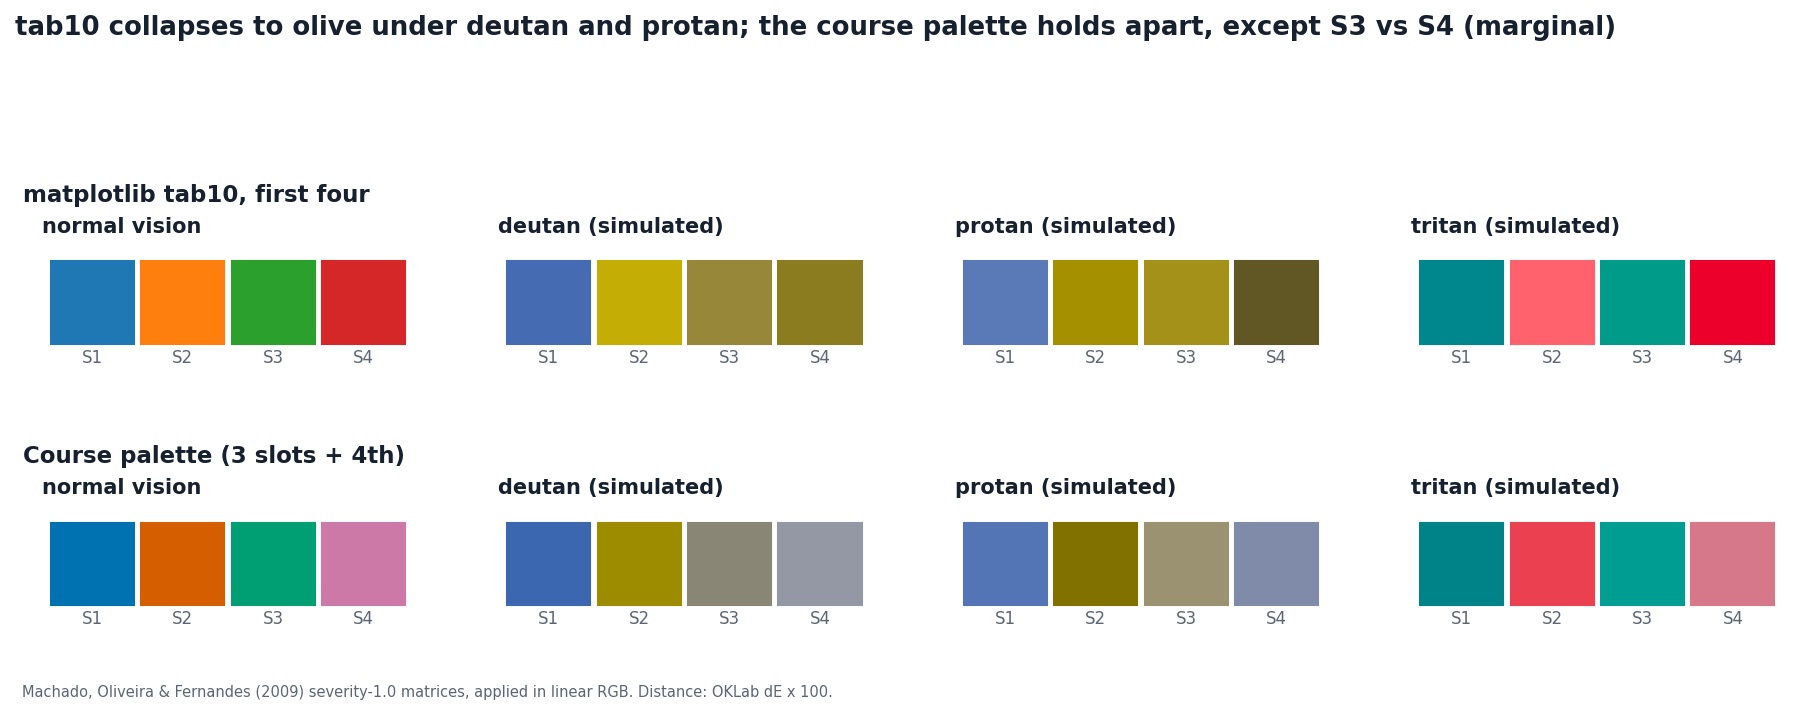

wrote week3/assignments/outputs/partC_palette.png


In [ ]:
# ------------------------------------------------------------------ the two palettes
# Q1: a palette I like the look of, NOT one I already believed was safe.
# matplotlib's tab10 (first four) is everywhere, and has a red AND a green in it.
MY_PALETTE = ["#1F77B4", "#FF7F0E", "#2CA02C", "#D62728"]
MY_LABEL   = "matplotlib tab10, first four"

# Q2: the course palette: 3 slots + the provided 4th slot
COURSE_PALETTE = PALETTE["series"] + [PALETTE["series_4th"]]
COURSE_LABEL   = "Course palette (3 slots + 4th)"
KINDS = ["normal", "deutan", "protan", "tritan"]

def swatch_sheet(palettes, path):
    fig, axes = plt.subplots(len(palettes), len(KINDS),
                             figsize=(3.0 * len(KINDS), 2.2 * len(palettes)))
    for row, (pal, label) in enumerate(palettes):
        for col, kind in enumerate(KINDS):
            ax = axes[row, col]
            shown = pal if kind == "normal" else simulate_cvd(pal, kind)
            for i, hexc in enumerate(shown):
                ax.add_patch(plt.Rectangle((i, 0), 0.92, 1, color=hexc))
                ax.text(i + 0.46, -0.22, f"S{i+1}", ha="center", fontsize=8, color=PALETTE["ink_soft"])
            ax.set_xlim(-0.1, len(pal)); ax.set_ylim(-0.4, 1.1)
            ax.axis("off")
            ax.set_title("normal vision" if kind == "normal" else f"{kind} (simulated)", fontsize=10)
        axes[row, 0].text(-0.05, 1.42, label, transform=axes[row, 0].transAxes,
                          fontsize=11, fontweight="bold", color=PALETTE["ink"])
    fig.suptitle("tab10 collapses to olive under deutan and protan; the course palette holds apart, except S3 vs S4 (marginal)",
                 x=0.006, ha="left", fontsize=12.5, fontweight="bold", color=PALETTE["ink"])
    fig.tight_layout(rect=[0, 0, 1, 0.9])
    out = save_fig(fig, path, "Machado, Oliveira & Fernandes (2009) severity-1.0 matrices, applied in linear RGB. Distance: OKLab dE x 100.")
    plt.show()
    return out

print("wrote", swatch_sheet([(MY_PALETTE, MY_LABEL), (COURSE_PALETTE, COURSE_LABEL)],
                            OUT / "partC_palette.png"))

## Q1 · Before/after swatches for my palette (3 marks)
The sheet above is the before (*normal vision*) and after (*deutan / protan / tritan*) for tab10 (top row). Now the numbers behind the impression:

In [ ]:
def audit(pal, label):
    rows = []
    for kind in KINDS:
        i, j, a, b, d = worst_pair(pal, kind)
        rows.append({"vision": kind, "closest pair": f"S{i} {a} vs S{j} {b}",
                     "dE": round(d, 1), "verdict": verdict(d)})
    print(label)
    display(pd.DataFrame(rows).set_index("vision"))
    return rows

mine   = audit(MY_PALETTE, MY_LABEL)

matplotlib tab10, first four


,closest pair,dE,verdict
vision,,,
normal,S2 #FF7F0E vs S4 #D62728,18.6,clear
deutan,S3 #2CA02C vs S4 #D62728,4.1,FAILS — same colour
protan,S2 #FF7F0E vs S3 #2CA02C,0.7,FAILS — same colour
tritan,S1 #1F77B4 vs S3 #2CA02C,6.7,needs a second channel


**Reading it:** to someone with normal vision tab10 is fine (worst pair ΔE 18.6). Under **deuteranopia** green (S3) vs red (S4) collapses to ΔE 4.1, and under **protanopia** orange (S2) vs green (S3) to ΔE 0.7, which is the same colour. Under **tritanopia** blue vs green is 6.7, which is legal only with a second channel. A chart using tab10 as its only encoding fails for roughly 1 reader in 12 men.

## Q2 · The course palette, plus the fourth slot (2 marks)

In [ ]:
course = audit(COURSE_PALETTE, COURSE_LABEL)

print("Same, with only the three course slots:")
course3 = audit(PALETTE["series"], "Course palette, 3 slots only")

Course palette (3 slots + 4th)


,closest pair,dE,verdict
vision,,,
normal,S2 #D55E00 vs S4 #CC79A7,16.4,clear
deutan,S3 #009E73 vs S4 #CC79A7,7.5,needs a second channel
protan,S1 #0072B2 vs S4 #CC79A7,9.5,ok
tritan,S1 #0072B2 vs S3 #009E73,8.4,ok


Same, with only the three course slots:
Course palette, 3 slots only


,closest pair,dE,verdict
vision,,,
normal,S1 #0072B2 vs S3 #009E73,18.7,clear
deutan,S2 #D55E00 vs S3 #009E73,11.0,ok
protan,S2 #D55E00 vs S3 #009E73,13.0,ok
tritan,S1 #0072B2 vs S3 #009E73,8.4,ok


## Q3 · The worst pair in each palette (2 marks)

In [ ]:
def overall_worst(pal):
    """The closest pair across ALL four vision types."""
    best = None
    for kind in KINDS:
        i, j, a, b, d = worst_pair(pal, kind)
        if best is None or d < best[-1]:
            best = (kind, i, j, a, b, d)
    return best

summary = []
for label, pal in [(MY_LABEL, MY_PALETTE), ("Course, 3 slots", PALETTE["series"]), (COURSE_LABEL, COURSE_PALETTE)]:
    k, i, j, a, b, d = overall_worst(pal)
    summary.append({"palette": label, "worst under": k, "pair": f"S{i} {a} vs S{j} {b}",
                    "dE": round(d, 1), "verdict": verdict(d)})
display(pd.DataFrame(summary).set_index("palette"))

,worst under,pair,dE,verdict
palette,,,,
"matplotlib tab10, first four",protan,S2 #FF7F0E vs S3 #2CA02C,0.7,FAILS — same colour
"Course, 3 slots",tritan,S1 #0072B2 vs S3 #009E73,8.4,ok
Course palette (3 slots + 4th),deutan,S3 #009E73 vs S4 #CC79A7,7.5,needs a second channel


| Palette | Worst pair | ΔE | Verdict |
|---|---|---|---|
| tab10, first four | orange vs green under **protanopia** | **0.7** | fails: same colour (red vs green under deutan is 4.1, also a fail) |
| Course, 3 slots | blue `#0072B2` vs green `#009E73` under **tritanopia** (and orange vs green under deutan at 11.0) | **8.4** | ok, just above the 8 target |
| Course, 3 slots + 4th | green `#009E73` vs pink `#CC79A7` under **deuteranopia** | **7.5** | needs a second channel |

**Yes, the course palette has one too, and it is the fourth slot.** In the 6–8 band, S3 and S4 are only distinguishable by an extra cue. That limits how I may use the colour: **`#CC79A7` may only appear when the chart also carries direct labels, a different marker shape, or a table view**, never as the sole carrier of identity. The three-slot set has no pair below 8.4, so it is the one I can use unaided.

## Q4 · The rule I will follow when a chart needs more than three categories (2 marks)

In [ ]:
i, j, a, b, d = worst_pair(COURSE_PALETTE, "deutan")
print(f"Fourth slot under deuteranopia: S{i} {a} vs S{j} {b}  dE {d:.1f}  -> {verdict(d)}")
print("Simulated 4th slot:", simulate_cvd(COURSE_PALETTE, "deutan")[3], " vs its neighbour:", simulate_cvd(COURSE_PALETTE, "deutan")[2])

Fourth slot under deuteranopia: S3 #009E73 vs S4 #CC79A7  dE 7.5  -> needs a second channel
Simulated 4th slot: #9498A5  vs its neighbour: #8A8676


> **My rule:** *Never add a colour to add a category. Add a second channel.* Up to three categories, use the three course slots. For a fourth or more, keep to **at most three hues** and make identity redundant: **direct labels** on the marks or lines, a **different marker shape** per category (`vizlib.MARKERS`), line style or texture, or **small multiples / a sorted table**. If the fourth slot (`#CC79A7`) is used at all, the chart must carry direct labels or a table view.

The evidence is above: under deuteranopia the fourth slot becomes `#9498A5`, a grey-blue next to the green's `#8A8676`, and ΔE falls from 25.4 (normal vision) to 7.5. Another hue doesn't fix that; a label does.

## Optional bonus · Run the simulation on a rendered figure (2 bonus marks)
Uses `outputs/partD_figure.png` (run Part D first). If the file is missing, this cell just says so.

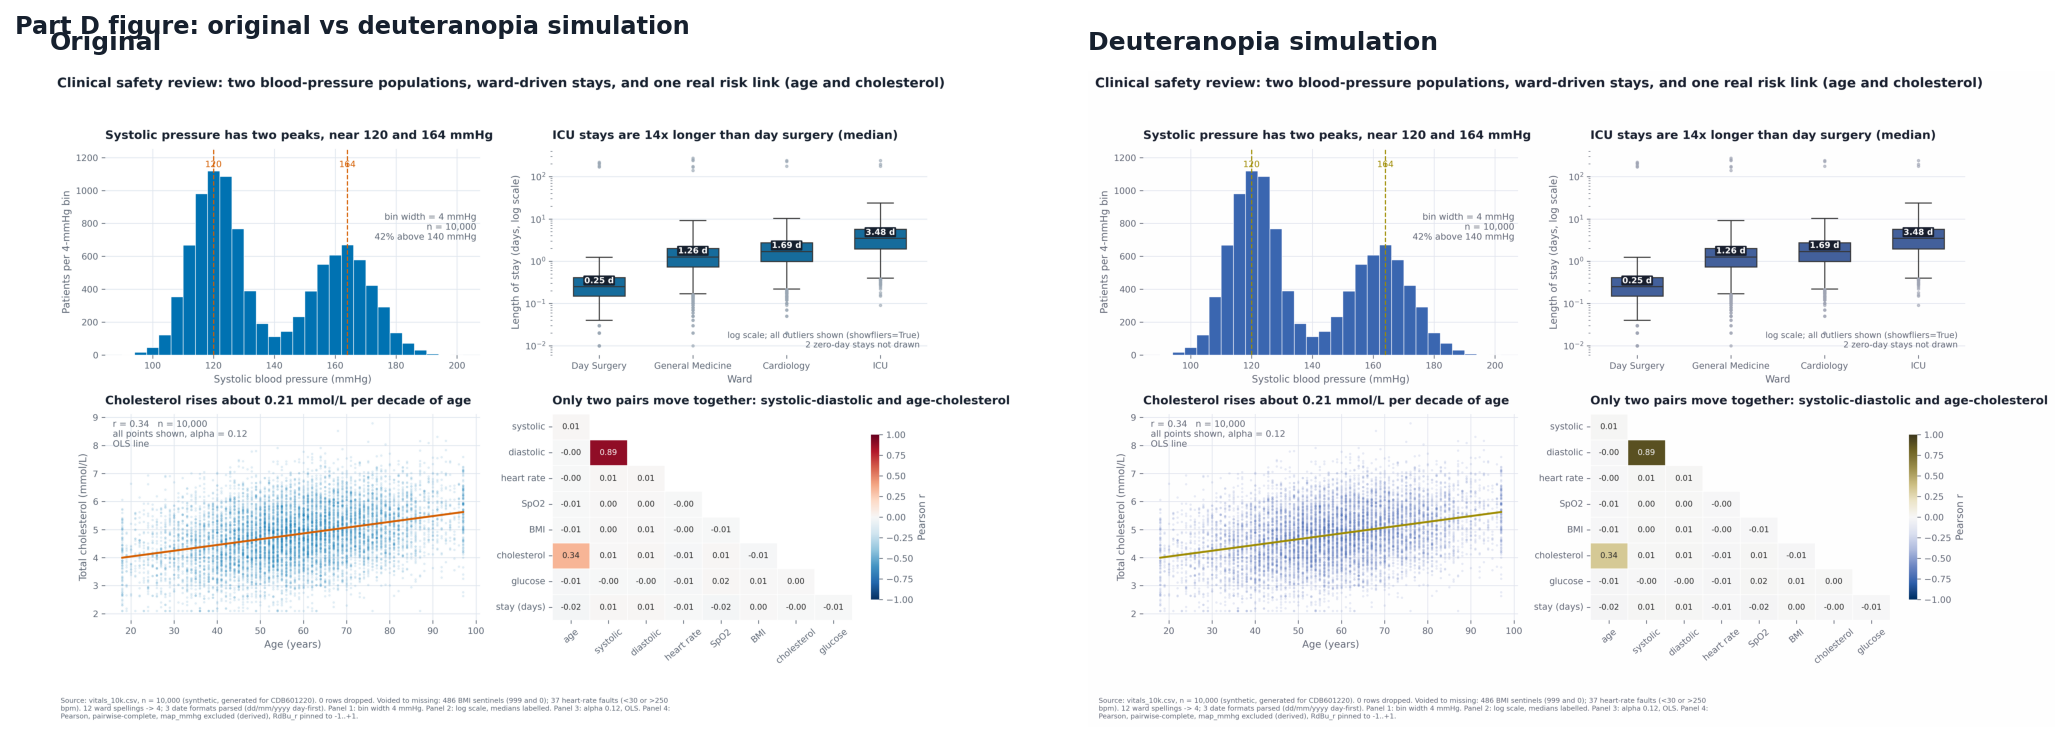

In [ ]:
import matplotlib.image as mpimg
src = OUT / "partD_figure.png"
if not src.exists():
    print("partD_figure.png not found; run Part D first, then re-run this cell.")
else:
    img = mpimg.imread(src)[..., :3]
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].imshow(img);                              axes[0].set_title("Original")
    axes[1].imshow(simulate_cvd(img, "deutan"));      axes[1].set_title("Deuteranopia simulation")
    for a in axes:
        a.axis("off")
    fig.suptitle("Part D figure: original vs deuteranopia simulation",
                 x=0.006, ha="left", fontsize=11.5, fontweight="bold")
    fig.tight_layout()
    fig.savefig(OUT / "partC_partD_deutan_check.png", dpi=200, bbox_inches="tight")
    plt.show()